# Reading handwritten digits with neural networks

Classifying the MNIST handwritten digits with fully connected neural networks in TensorFlow/Keras, and comparing one, two and three hidden layers.

**Authors:** Ido Shalom, Daniel Rodan

## Classifying MNIST digits

### Section A

In [26]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras.utils import to_categorical, plot_model
from sklearn.metrics import confusion_matrix
from keras.layers import Dense, Input

# Ignore warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module='keras')

In [27]:
# Set seed
np.random.seed(9)

In [28]:
# Download the data
(X_train, y_train),(X_test, y_test) = mnist.load_data()

11490434/11490434 [==============================] - 1s 0us/step


In [29]:
# Print the shapes of the datasets
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (60000, 28, 28), y_train shape: (60000,)
X_test shape: (10000, 28, 28), y_test shape: (10000,)


In [30]:
# Each observation represents an image of size 28x28
image_size = X_train.shape[1]
input_size = image_size * image_size

# Flatten each observation to a vector of length 784
X_train = X_train.reshape((X_train.shape[0], -1))
X_test = X_test.reshape((X_test.shape[0], -1))

# Print the Flatten shapes 
print(f"Flatten shapes -> X_train: {X_train.shape}")
print(f"Flatten shapes -> X_test: {X_test.shape}")

Flatten shapes -> X_train: (60000, 784)
Flatten shapes -> X_test: (10000, 784)


### Section B

In [31]:
# Number of classes for classification
num_classes = 10

# Convert class vectors to binary class matrices 
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

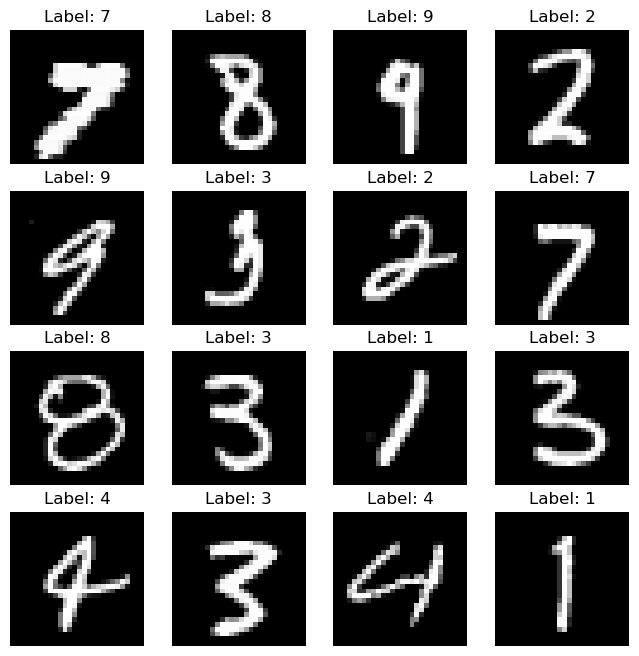

In [32]:
# Function to display an image from a flattened vector
def display_image_from_vector(observation, label):
    image = observation.reshape((28, 28))
    plt.imshow(image, cmap='gray')
    plt.title(f"Label: {label}")
    plt.axis('off')

# Number of random images 
num_images = 16

# Select random indices from the training set
random_indices = np.random.choice(X_train.shape[0], num_images, replace=False)

# Create a figure to display the images
plt.figure(figsize=(8, 8))
for i, index in enumerate(random_indices):
    plt.subplot(4, 4, i + 1)
    display_image_from_vector(X_train[index], np.argmax(y_train[index]))
plt.show()

### Section C

In [33]:
# Model 1 - Single Hidden Layer
model_1 = Sequential()

# Input Layer
model_1.add(Input(shape=(784,)))

# First Layer 
model_1.add(Dense(units=512, input_shape=(784,), activation='relu'))

# Output Layer
model_1.add(Dense(units=10, activation='softmax'))

**Why did we choose this number of neurons and this activation function?**


- We chose 10 neurons for the output layer because our task is to classify handwritten digits from 0 to 9, requiring one neuron for each possible digit.

- The softmax activation function was selected for the output layer because it converts the raw output scores from the network into probabilities, allowing us to interpret the network's output as the probability of each digit being the correct classification.


### Section D

In [34]:
# Setup the model
model_1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])
model_1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               401920    
                                                                 
 dense_1 (Dense)             (None, 10)                5130      
                                                                 
Total params: 407050 (1.55 MB)
Trainable params: 407050 (1.55 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [35]:
# Train the model 
model_1.fit(
    X_train, y_train,  
    epochs=3,  
    batch_size=32  # Number of samples per gradient update
)

# Evaluate the model on the test data
test_loss_1, test_acc_1 = model_1.evaluate(X_test, y_test)

# Print the test accuracy 
print(f'Test accuracy: {test_acc_1:.5f}')

Epoch 1/3
1875/1875 [==============================] - 23s 11ms/step - loss: 0.3841 - accuracy: 0.9223
Epoch 2/3
1875/1875 [==============================] - 24s 13ms/step - loss: 0.0456 - accuracy: 0.9564
Epoch 3/3
313/313 [==============================] - 2s 5ms/step - loss: 0.0406 - accuracy: 0.9568
Test accuracy: 0.95680


### Section E

In [36]:
# Model 2 - Two Hidden Layers
model_2 = Sequential()

# Input Layer
model_2.add(Input(shape=(784,)))

# First Layer
model_2.add(Dense(units=512, activation='relu'))

# Second Layer (the added one)
model_2.add(Dense(units=256, activation='relu'))

# Output Layer 
model_2.add(Dense(units=10, activation='softmax'))

In [37]:
# Setup the new model
model_2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])
model_2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_2 (Dense)             (None, 512)               401920    
                                                                 
 dense_3 (Dense)             (None, 256)               131328    
                                                                 
 dense_4 (Dense)             (None, 10)                2570      
                                                                 
Total params: 535818 (2.04 MB)
Trainable params: 535818 (2.04 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [38]:
# Train the new model 
model_2.fit(
    X_train, y_train,  
    epochs=3,  
    batch_size=32  # Number of samples per gradient update
)

# Evaluate the new model 
test_loss_2, test_acc_2 = model_2.evaluate(X_test, y_test)

# Print the test accuracy 
print(f'Test accuracy: {test_acc_2:.5f}')

Epoch 1/3
1875/1875 [==============================] - 33s 17ms/step - loss: 0.1957 - accuracy: 0.9204
Epoch 2/3
1875/1875 [==============================] - 29s 15ms/step - loss: 0.0317 - accuracy: 0.9589
Epoch 3/3
313/313 [==============================] - 2s 6ms/step - loss: 0.0282 - accuracy: 0.9614
Test accuracy: 0.96140


In [39]:
# Single Hidden Layer Model
model_1_name = "Single Hidden Layer Model"
model_1_test_accuracy = test_acc_1

# Two Hidden Layers Model
model_2_name = "Two Hidden Layers Model"
model_2_test_accuracy = test_acc_2

# Print the summary of the results
print(f"{model_1_name}\nTest Accuracy: {model_1_test_accuracy:.5f}\n")
print(f"{model_2_name}\nTest Accuracy: {model_2_test_accuracy:.5f}\n")

Single Hidden Layer Model
Test Accuracy: 0.95680

Two Hidden Layers Model
Test Accuracy: 0.96140



**Summery of Results so Far:**

We thought that it would be appropriate to set the second layer to have 256 neurons and to use the ReLU activation function for this layer, as it is not the output layer.

It seems that the additional hidden layer contributes to the overall performance of the model.


In [40]:
# Model 3 - Three Hidden Layers 
model_3 = Sequential()

# Input Layer
model_3.add(Input(shape=(784,)))

# First Layer
model_3.add(Dense(units=512, activation='relu'))

# Second Layer
model_3.add(Dense(units=256, activation='relu'))

# Third Layer (the one we try to add now)
model_3.add(Dense(units=128, activation='relu'))

# Output Layer 
model_3.add(Dense(units=10, activation='softmax'))

In [41]:
# Setup the Last model
model_3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])
model_3.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 512)               401920    
                                                                 
 dense_6 (Dense)             (None, 256)               131328    
                                                                 
 dense_7 (Dense)             (None, 128)               32896     
                                                                 
 dense_8 (Dense)             (None, 10)                1290      
                                                                 
Total params: 567434 (2.16 MB)
Trainable params: 567434 (2.16 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [42]:
# Train the Last model 
model_3.fit(
    X_train, y_train,  
    epochs=3,  
    batch_size=32  # Number of samples per gradient update
)

# Evaluate the Last model 
test_loss_3, test_acc_3 = model_3.evaluate(X_test, y_test)

# Print the test accuracy 
print(f'Test accuracy: {test_acc_3:.5f}')

Epoch 1/3
1875/1875 [==============================] - 32s 16ms/step - loss: 0.1273 - accuracy: 0.9196
Epoch 2/3
1875/1875 [==============================] - 26s 14ms/step - loss: 0.0283 - accuracy: 0.9600
Epoch 3/3
313/313 [==============================] - 2s 6ms/step - loss: 0.0223 - accuracy: 0.9661
Test accuracy: 0.96610


In [43]:
# Three Hidden Layers Model
model_3_name = "Three Hidden Layers Model"
model_3_test_accuracy = test_acc_3

# Print the summary of the results
print(f"Single Hidden Layer Model\nTest Accuracy: {model_1_test_accuracy:.5f}\n")
print(f"Two Hidden Layers Model\nTest Accuracy: {model_2_test_accuracy:.5f}\n")
print(f"Three Hidden Layers Model\nTest Accuracy: {model_3_test_accuracy:.5f}\n")

Single Hidden Layer Model
Test Accuracy: 0.95680

Two Hidden Layers Model
Test Accuracy: 0.96140

Three Hidden Layers Model
Test Accuracy: 0.96610



**Did we improve the model?**

In our case, the 'Three Hidden Layers Model' achieved the highest accuracy, surpassing both the 'Two Hidden Layers Model' and the 'Single Hidden Layer Model.' This shows that adding more layers can enhance performance, but not always predictably or significantly. It emphasizes that model improvement doesn't follow a simple 'more layers, better performance' rule. Instead, finding the optimal model requires careful tuning and consideration of hyperparameters.


### Section F

313/313 [==============================] - 2s 5ms/step


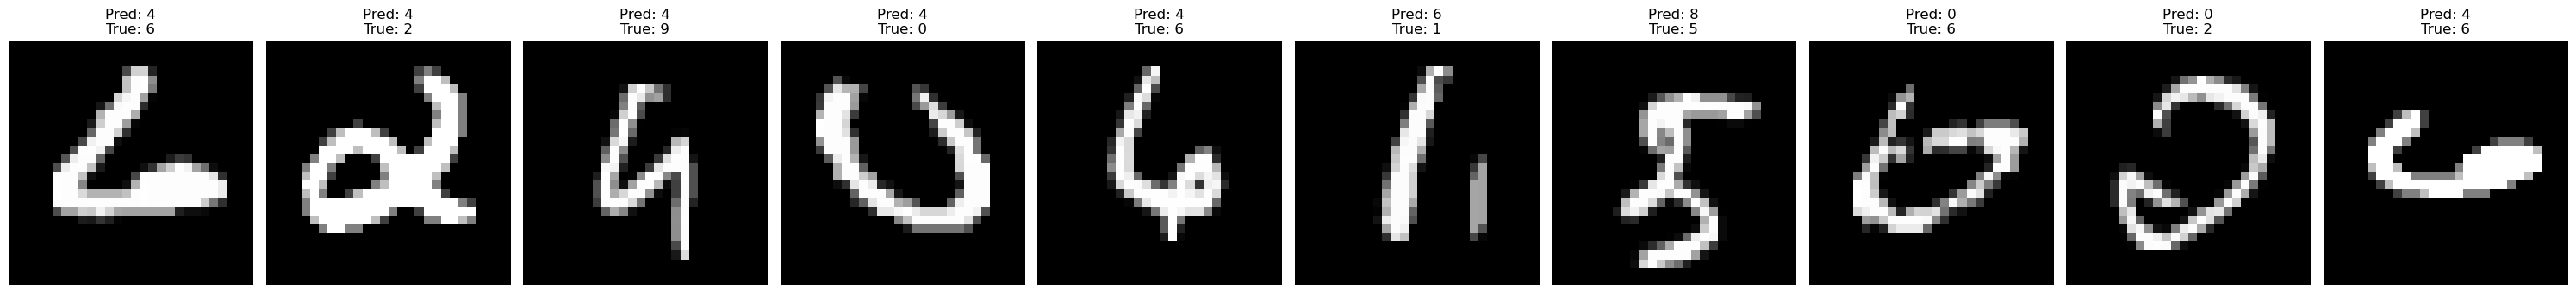

Total misclassified images: 339


In [44]:
# Best model - Three Hidden Layers Model
y_pred = model_3.predict(X_test) 
y_pred_classes = np.argmax(y_pred, axis=1)  
y_true = np.argmax(y_test, axis=1)  

# Misclassified samples
errors = (y_pred_classes != y_true)  
y_pred_classes_errors = y_pred_classes[errors]  
y_pred_errors = y_pred[errors]  
y_true_errors = y_true[errors]  
X_test_errors = X_test[errors]  

# Probabilities of predicted 
y_pred_errors_probability = np.max(y_pred_errors, axis=1)  
true_probability_errors = np.diagonal(np.take(y_pred_errors, y_true_errors, axis=1))  
diff_errors_pred_true = y_pred_errors_probability - true_probability_errors  

# List of indices of sorted differences
sorted_idx_diff_errors = np.argsort(diff_errors_pred_true)  
top_idx_diff_errors = sorted_idx_diff_errors[-10:]  

# Top misclassified images
num = len(top_idx_diff_errors)  
f, ax = plt.subplots(1, num, figsize=(30, 30))  

for i in range(num):
    idx = top_idx_diff_errors[i]  
    sample = X_test_errors[idx].reshape(28, 28)  
    y_t = y_true_errors[idx]  
    y_p = y_pred_classes_errors[idx]  
    ax[i].imshow(sample, cmap='gray')  
    ax[i].set_title(f"Pred: {y_p}\nTrue: {y_t}", fontsize=12)  
    ax[i].axis('off')  

plt.tight_layout()  
plt.show() 

# Number of misclassified images
print(f"Total misclassified images: {len(y_pred_classes_errors)}") 

**Note:**

- We chose the hreewo Hidden Layers Model" as our best model, as shown above.
  
- We only display the top 10 high-error misclassified images for better visual clarity.


### Section G

**Summary of our work in question 2:**

Overall, we feel that the network performed the classification well.

We observed how significant the correct determination of hyperparameters in the model can be, and that adding more layers does not necessarily lead to better results.

The last section of the question was particularly interesting because, in some cases, you can actually see why there might have been an error in the prediction beyond mathematical formulas.

If we had to classify these photos correctly based on our own judgment, we would probably make significant errors as well.